# MC2 · Pattern Detection · Day 6 – Technical Implementation
**Algorithm: Hough circle transform**, including the edge detection that provides its input.

*Scope: step-wise implementation, intermediate results, and verification on a synthetic test image. No use case, parameter tuning or evaluation (Days 7–10).*

Circular patterns are frequent in Japanese images (festival crests, flags, lantern openings, manhole covers); the transform consists of clearly separable steps with an informative intermediate result, the accumulator.

## 1. Algorithm
A circle with centre $(a,b)$ and radius $r$ satisfies $(x-a)^2+(y-b)^2=r^2$. The Hough transform maps edge pixels to this parameter space: an edge pixel $(x,y)$ is consistent with all circles of radius $r$ whose centre lies at distance $r$ from it, i.e. on a circle around $(x,y)$ in the $(a,b)$ plane. Each edge pixel adds one vote to every such cell of an accumulator $A[r,b,a]$. The cell of a true circle collects the votes of all its edge pixels; local maxima of $A$ are the detected circles.

| # | Step | Operation | Parameter |
|---|---|---|---|
| 1 | smoothing | Gaussian filter, noise suppression before differentiation | $\sigma$ |
| 2 | gradient | Sobel operator: $G_x$, $G_y$, $\lvert G\rvert$, direction $\theta$ | – |
| 3 | thinning | non-maximum suppression along $\theta$ | – |
| 4 | edge map | threshold on the thinned magnitude | `EDGE_FRAC` |
| 5 | voting, peaks | accumulator over $(r,y,x)$, local maxima, minimum separation | `RADII`, `PEAK_THR`, `MIN_SEP` |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi

# ---------------- parameters (all in one place, nothing is tuned on this day) ----------------
SIGMA      = 1.5               # Gaussian blur [px]
EDGE_FRAC  = 0.20              # edge threshold as a fraction of the maximum thinned gradient magnitude
RADII      = np.arange(12, 61) # radii searched [px]
PEAK_THR   = 0.60              # minimum normalised accumulator value for a circle (see step 5)
MIN_SEP    = 10                # minimum distance between two detected circles in (x, y, r) [px]
print(f"sigma={SIGMA}px | edge threshold={EDGE_FRAC} x max | radii {RADII.min()}..{RADII.max()} px | peak threshold={PEAK_THR} | min separation={MIN_SEP}px")

sigma=1.5px | edge threshold=0.2 x max | radii 12..60 px | peak threshold=0.6 | min separation=10px


## 2. Test image
Synthetic image (240 × 240 px) with known content: three dark discs (radii 18, 28, 45 px) on a bright background, a rectangle as non-circular distractor, and Gaussian noise ($\sigma=4$ grey levels). Ground truth $(x,y,r,\text{value})$ is stored in `truth`.

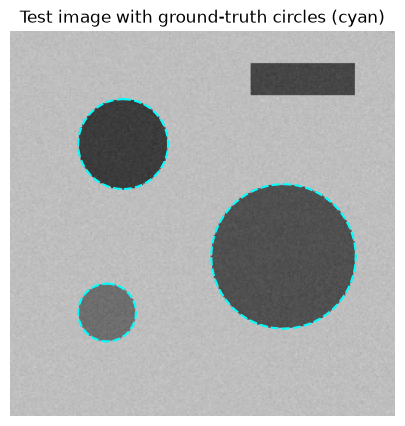

In [2]:
def make_test_image(seed=0):
    H = W = 240
    yy, xx = np.mgrid[0:H, 0:W]
    img = np.full((H, W), 190.0)
    truth = [(70, 70, 28, 60), (170, 140, 45, 80), (60, 175, 18, 110)]   # (cx, cy, r, grey value)
    for cx, cy, r, v in truth:
        img[(xx - cx) ** 2 + (yy - cy) ** 2 <= r ** 2] = v
    img[20:40, 150:215] = 70                                            # non-circular distractor
    img += np.random.default_rng(seed).normal(0, 4, img.shape)          # sensor-like noise
    return np.clip(img, 0, 255), truth

test, truth = make_test_image()
fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(test, cmap="gray", vmin=0, vmax=255)
for cx, cy, r, _ in truth:
    ax.add_patch(plt.Circle((cx, cy), r, fill=False, ec="cyan", ls="--", lw=1.5))
ax.set_title("Test image with ground-truth circles (cyan)"); ax.axis("off")
plt.show()

**Figure A1.** Test image (input of the algorithm) with the ground-truth circles (cyan, dashed). The ground truth is shown for verification only and is not used by the algorithm. The three radii test the radius search; the rectangle tests the rejection of straight edges.

## 3. Implementation
**Step 1 – Smoothing.** A Gaussian filter of width $\sigma$ reduces noise, which differentiation would amplify.

**Step 2 – Sobel gradient.**
$$K_x=\begin{pmatrix}-1&0&1\\-2&0&2\\-1&0&1\end{pmatrix},\quad K_y=K_x^{T},\qquad \lvert G\rvert=\sqrt{G_x^2+G_y^2},\quad \theta=\operatorname{atan2}(G_y,G_x)$$
$\lvert G\rvert$ is large at intensity transitions; $\theta$ points across the edge.

**Step 3 – Non-maximum suppression.** $\lvert G\rvert$ is kept at a pixel only if it is maximal compared with its two neighbours along $\theta$ (quantised to 0°, 45°, 90°, 135°). The result is an edge of about one pixel width, which limits the number of votes per edge.

**Step 4 – Edge map.** Pixels with thinned magnitude $\ge$ `EDGE_FRAC` $\cdot \max$ form the binary edge map.

In [3]:
def smooth(img, sigma):
    return ndi.gaussian_filter(img, sigma, mode="reflect")                       # step 1

def sobel(img):
    kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=float)            # step 2
    gx = ndi.correlate(img, kx, mode="reflect")
    gy = ndi.correlate(img, kx.T, mode="reflect")
    return gx, gy, np.hypot(gx, gy), np.arctan2(gy, gx)

def non_max_suppression(mag, ang):
    a = np.rad2deg(ang) % 180                                                    # step 3
    q = np.select([a < 22.5, a < 67.5, a < 112.5, a < 157.5], [0, 1, 2, 3], 0)  # direction class
    shifts = {0: (0, 1), 1: (1, 1), 2: (1, 0), 3: (1, -1)}                       # (dy, dx) along the gradient
    out = np.zeros_like(mag)
    for k, (dy, dx) in shifts.items():
        n1 = np.roll(mag, (-dy, -dx), axis=(0, 1))
        n2 = np.roll(mag, (dy, dx), axis=(0, 1))
        keep = (q == k) & (mag > n1) & (mag >= n2)
        out[keep] = mag[keep]
    out[0, :] = out[-1, :] = 0; out[:, 0] = out[:, -1] = 0                       # remove wrap-around at the border
    return out

def edge_map(nms, frac):
    return nms >= frac * nms.max()                                               # step 4

blurred            = smooth(test, SIGMA)
gx, gy, mag, ang   = sobel(blurred)
nms                = non_max_suppression(mag, ang)
edges              = edge_map(nms, EDGE_FRAC)
print(f"edge pixels: {int(edges.sum())} of {edges.size} ({100 * edges.mean():.1f} %)")

edge pixels: 838 of 57600 (1.5 %)


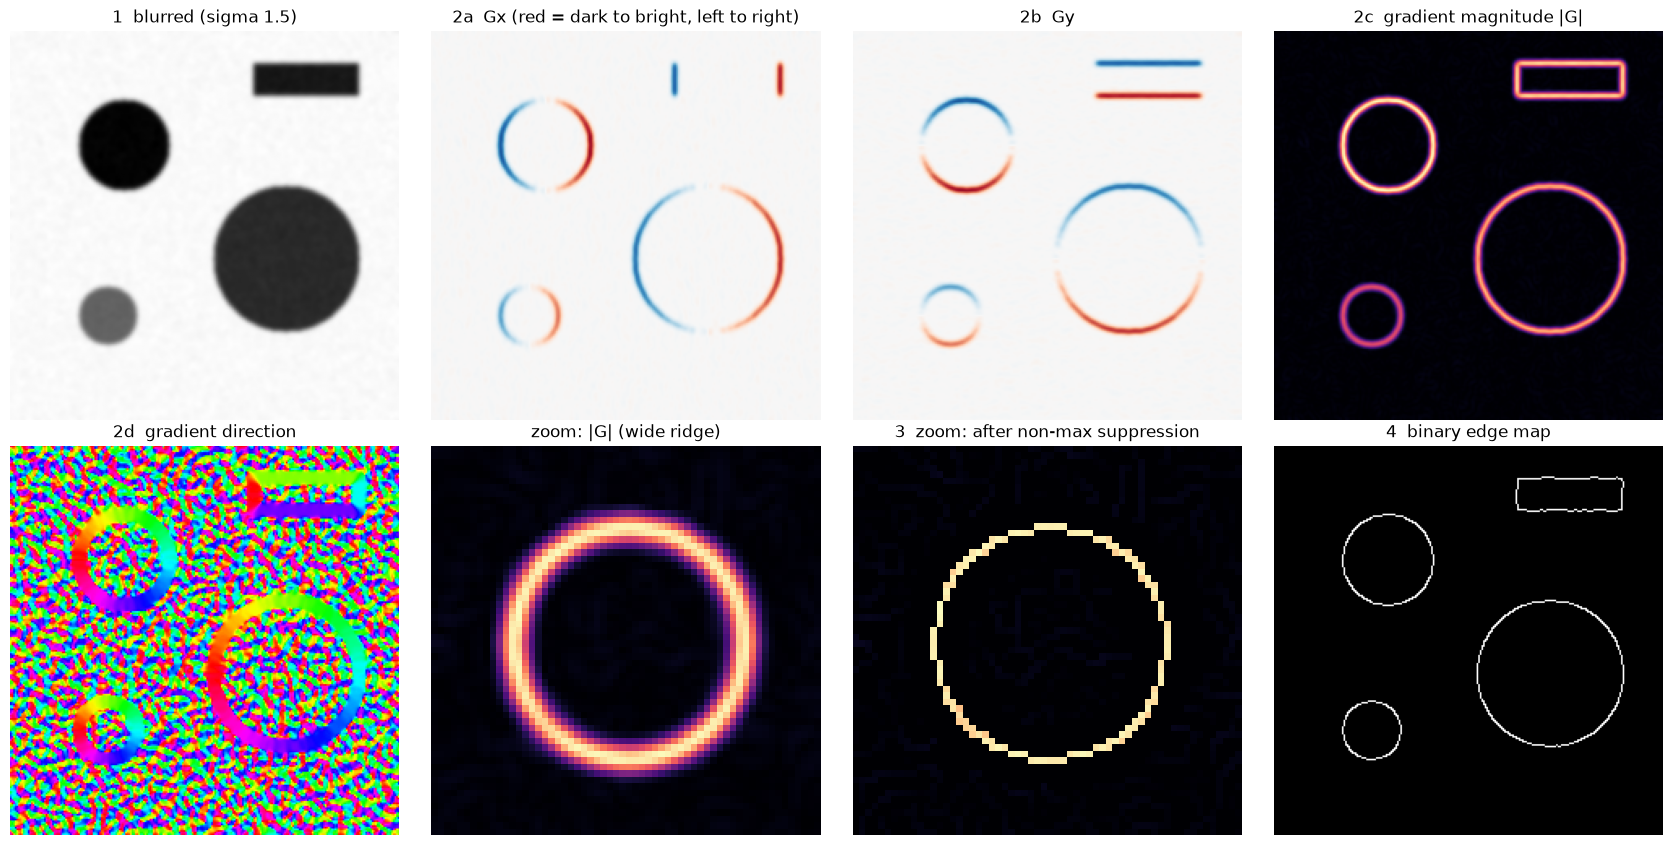

In [4]:
zx, zy = slice(145, 205), slice(30, 90)       # zoom on the smallest disc
fig, axs = plt.subplots(2, 4, figsize=(17, 8.5))
axs[0, 0].imshow(blurred, cmap="gray");                  axs[0, 0].set_title("1  blurred (sigma 1.5)")
axs[0, 1].imshow(gx, cmap="RdBu_r", vmin=-300, vmax=300); axs[0, 1].set_title("2a  Gx (red = dark to bright, left to right)")
axs[0, 2].imshow(gy, cmap="RdBu_r", vmin=-300, vmax=300); axs[0, 2].set_title("2b  Gy")
axs[0, 3].imshow(mag, cmap="magma");                     axs[0, 3].set_title("2c  gradient magnitude |G|")
axs[1, 0].imshow(ang, cmap="hsv", vmin=-np.pi, vmax=np.pi); axs[1, 0].set_title("2d  gradient direction")
axs[1, 1].imshow(mag[zx, zy], cmap="magma", interpolation="nearest"); axs[1, 1].set_title("zoom: |G| (wide ridge)")
axs[1, 2].imshow(nms[zx, zy], cmap="magma", interpolation="nearest"); axs[1, 2].set_title("3  zoom: after non-max suppression")
axs[1, 3].imshow(edges, cmap="gray");                    axs[1, 3].set_title("4  binary edge map")
for a in axs.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

**Figure A2.** Edge detection steps. *1:* smoothed image. *2a, 2b:* Sobel derivatives $G_x$, $G_y$ (red positive, blue negative); $G_x$ responds to vertical, $G_y$ to horizontal edges, with opposite sign on opposite sides of a disc. *2c:* gradient magnitude; all outlines, including the rectangle, form ridges. *2d:* gradient direction; around each disc the angle runs through the full circle because the gradient is directed along the radius. *Zoom, |G| vs. NMS:* the ridge of several pixels width is reduced to a thin line. *4:* binary edge map, the input of the Hough transform.

**Step 5 – Voting and peak detection.** For each radius $r\in$ `RADII` and each edge pixel $(x,y)$, one vote is added to the cells $(a,b)=(x+r\cos t,\;y+r\sin t)$ for $n_r=\lceil 2\pi r\rceil$ angles $t$ (about one sample per circumference pixel). The accumulator has one 2-D layer per radius.

*Normalisation.* Layer $r$ is divided by $n_r$, so that the value approximates the fraction of the circumference covered by edge pixels (≈ 1 for a complete circle) and `PEAK_THR` is comparable across radii.

*Peaks.* Local maxima in a $5\times5\times5$ neighbourhood with value $\ge$ `PEAK_THR` are sorted by value; a peak is accepted if its distance in $(a,b,r)$ to all accepted peaks is $\ge$ `MIN_SEP`.

In [5]:
def hough_circle_accumulator(edge, radii):
    H, W = edge.shape
    ys, xs = np.nonzero(edge)
    acc = np.zeros((len(radii), H, W), dtype=np.float32)
    for i, r in enumerate(radii):
        n = int(np.ceil(2 * np.pi * r))
        t = np.linspace(0, 2 * np.pi, n, endpoint=False)
        cy = np.rint(ys[:, None] + r * np.sin(t)[None, :]).astype(int).ravel()    # candidate centres of all edge pixels
        cx = np.rint(xs[:, None] + r * np.cos(t)[None, :]).astype(int).ravel()
        ok = (cy >= 0) & (cy < H) & (cx >= 0) & (cx < W)
        votes = np.bincount(cy[ok] * W + cx[ok], minlength=H * W)                   # voting
        acc[i] = votes.reshape(H, W) / n                                            # normalise by circumference
    return acc

def find_circles(acc, radii, thr, min_sep):
    local_max = acc == ndi.maximum_filter(acc, size=(5, 5, 5), mode="constant")
    idx = np.argwhere(local_max & (acc >= thr))
    order = np.argsort(-acc[tuple(idx.T)])
    found = []
    for ri, cy, cx in idx[order]:
        c = (cx, cy, radii[ri])
        if all(np.linalg.norm(np.subtract(c, f[:3])) >= min_sep for f in found):
            found.append((int(cx), int(cy), int(radii[ri]), float(acc[ri, cy, cx])))
    return found

acc = hough_circle_accumulator(edges, RADII)
circles = find_circles(acc, RADII, PEAK_THR, MIN_SEP)
print("accumulator shape (radii, y, x):", acc.shape, "| maximum value:", round(float(acc.max()), 2))
print("detected circles (x, y, r, accumulator value):")
for c in circles: print("  ", c[:3], round(c[3], 2))

accumulator shape (radii, y, x): (49, 240, 240) | maximum value: 0.95
detected circles (x, y, r, accumulator value):
   (170, 140, 45) 0.95
   (70, 70, 28) 0.9
   (60, 175, 18) 0.85


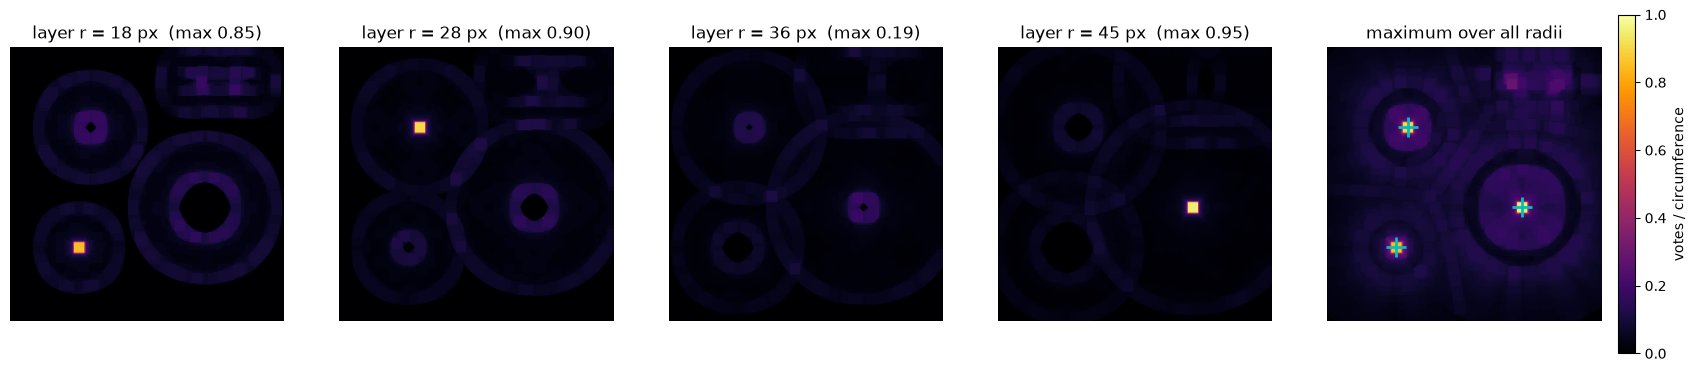

In [6]:
show_r = [18, 28, 36, 45]                                   # three true radii and one radius without a circle
fig, axs = plt.subplots(1, 5, figsize=(21, 4.4))
for a, r in zip(axs[:4], show_r):
    layer = acc[list(RADII).index(r)]
    m = a.imshow(ndi.maximum_filter(layer, size=9), cmap="inferno", vmin=0, vmax=1.0)   # 9x9 max filter for display only
    a.set_title(f"layer r = {r} px  (max {layer.max():.2f})"); a.axis("off")
axs[4].imshow(ndi.maximum_filter(acc.max(axis=0), size=9), cmap="inferno", vmin=0, vmax=1.0); axs[4].set_title("maximum over all radii"); axs[4].axis("off")
for cx, cy, r, _ in circles:
    axs[4].plot(cx, cy, "c+", ms=14, mew=2)
fig.colorbar(m, ax=axs, fraction=0.012, pad=0.01, label="votes / circumference")
plt.show()

**Figure A3.** Accumulator layers for $r=18, 28, 36, 45$ px and the maximum over all radii. Brightness is the normalised vote count; the number in each title is the layer maximum. Layers are drawn with a $9\times9$ maximum filter for visibility only (data unchanged). The layers $r=18, 28, 45$ each contain one peak at the centre of the disc of that radius (maxima 0.85, 0.90, 0.95); other discs contribute only weak ring-shaped structures. For $r=36$, no disc exists and the layer maximum is 0.19. In the maximum projection, each disc yields one peak at its centre (cyan crosses: accepted peaks).

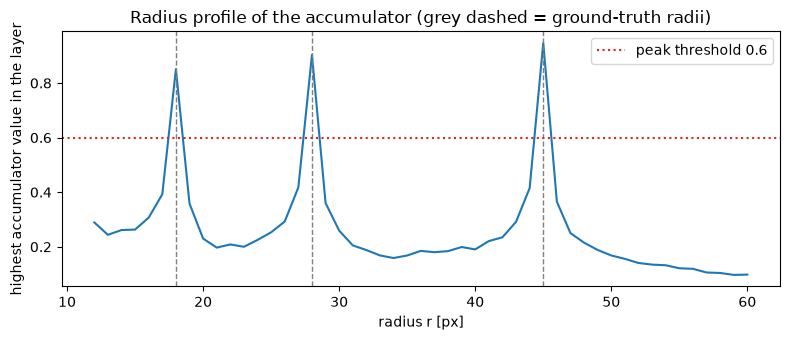

In [7]:
prof = acc.reshape(len(RADII), -1).max(axis=1)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(RADII, prof, color="tab:blue")
for _, _, r, _ in truth: ax.axvline(r, color="gray", ls="--", lw=1)
ax.axhline(PEAK_THR, color="tab:red", ls=":", label=f"peak threshold {PEAK_THR}")
ax.set_xlabel("radius r [px]"); ax.set_ylabel("highest accumulator value in the layer")
ax.set_title("Radius profile of the accumulator (grey dashed = ground-truth radii)"); ax.legend()
plt.tight_layout(); plt.show()

**Figure A4.** Maximum accumulator value per radius. Maxima occur at the radii of the three discs (grey dashed lines); between them the curve remains low. Only maxima above `PEAK_THR` (red dotted) can become detections. This is the radius axis of the accumulator, which the 2-D layers do not show.

## 4. Verification
The detections are compared with the ground truth of the test image (functional check of the implementation, not an evaluation of the method).

truth (x, y, r)     detected (x, y, r)    error dx, dy, dr    
(70, 70, 28)        (70, 70, 28)          (0, 0, 0)           
(170, 140, 45)      (170, 140, 45)        (0, 0, 0)           
(60, 175, 18)       (60, 175, 18)         (0, 0, 0)           

number of detections: 3 (ground truth: 3) | largest error: 0 px


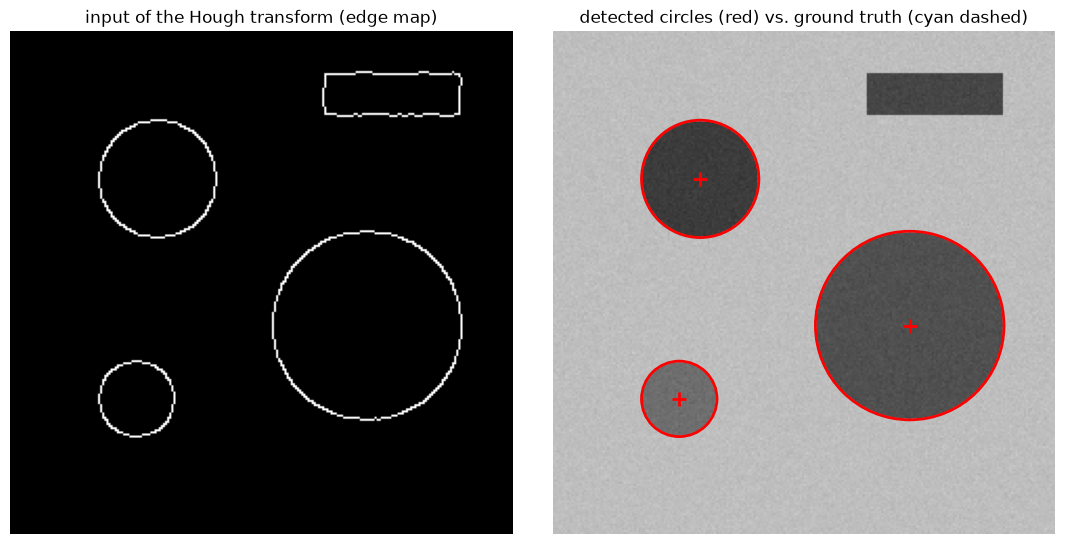

In [8]:
print(f"{'truth (x, y, r)':<20}{'detected (x, y, r)':<22}{'error dx, dy, dr':<20}")
errs = []
for cx, cy, r, _ in truth:
    d = min(circles, key=lambda c: np.hypot(c[0] - cx, c[1] - cy) + abs(c[2] - r))
    e = (d[0] - cx, d[1] - cy, d[2] - r); errs.append(max(abs(v) for v in e))
    print(f"{str((cx, cy, r)):<20}{str(tuple(int(v) for v in d[:3])):<22}{str(tuple(int(v) for v in e)):<20}")
print(f"\nnumber of detections: {len(circles)} (ground truth: {len(truth)}) | largest error: {max(errs)} px")
assert len(circles) == len(truth) and max(errs) <= 2, "verification failed"

fig, axs = plt.subplots(1, 2, figsize=(11, 5.4))
axs[0].imshow(edges, cmap="gray"); axs[0].set_title("input of the Hough transform (edge map)")
axs[1].imshow(test, cmap="gray", vmin=0, vmax=255); axs[1].set_title("detected circles (red) vs. ground truth (cyan dashed)")
for cx, cy, r, _ in truth:  axs[1].add_patch(plt.Circle((cx, cy), r, fill=False, ec="cyan", ls="--", lw=1.5))
for cx, cy, r, _ in circles:
    axs[1].add_patch(plt.Circle((cx, cy), r, fill=False, ec="red", lw=2)); axs[1].plot(cx, cy, "r+", ms=10, mew=2)
for a in axs: a.axis("off")
plt.tight_layout(); plt.show()

**Figure A5.** Left: edge map used as input. Right: detected circles (red) and ground truth (cyan, dashed) on the test image. The table above lists the deviation of centre and radius for each circle; the assertion terminates the notebook if the number of detections differs from the ground truth or the deviation exceeds 2 px. The rectangle produces no detection, since its straight edges do not vote consistently for a single centre.

---
# Day 7 · Data & Domain

## 1. Use case and problem statement
**Use case.** Each lantern of the kanto towers at the Akita Kanto Festival (Akita, Japan) carries one red circular crest (emblem of Akita City). Automatic cataloguing of festival photographs requires the number and positions of the lanterns of a tower. Since each lantern has exactly one crest, localising the crests yields the lantern count, the lantern grid and anchor points for cropping (e.g. for lettering recognition). The crest is more compact and more regular than the lantern, whose outline is occluded by bamboo bars and neighbouring lanterns.

**Problem.** In night photographs, crest localisation is impeded by
- numerous other curved edges (elliptical lantern outlines and openings),
- perspective: the crest size varies with height and its shape is slightly distorted,
- occlusion (bamboo bars, performers) and glow at the lantern rim,
- concentric inner structure: one crest yields several circular edges,
- low colour contrast (red on orange), which depends on the grey conversion.

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

IMG_PATH = "akita-kanto-festival-by-annintofu-flickr-2187739691.jpg"
img = np.array(Image.open(IMG_PATH).convert("RGB"))
H, W, _ = img.shape
print(f"image: {W} x {H} px, {img.shape[2]} channels, {img.dtype}")

# Regions (x0, x1, y0, y1) in original pixel coordinates, defined visually (not detected)
TOWER = (1010, 1360, 480, 960)    # right-hand tower with red crests
CREST = (1190, 1275, 560, 640)    # one lantern with its crest

image: 2048 x 1366 px, 3 channels, uint8


## 2. Image
**Origin.** Photograph "Akita Kanto Festival" by *annintofu* (Flickr), obtained via the Bunnik Tours photo gallery. No licence is stated; the image is used for non-commercial coursework with attribution. It is the image used in the augmentation notebook.

**Content.** Night scene, low viewpoint, 2048 × 1366 px, RGB. Two lantern towers in the centre (left: black lettering; right: red crests), two tilted towers in the background, performers in the foreground, black sky.

**Visual characteristics.**
- *Crests:* dark red emblems on bright orange paper, one per lantern, in a regular grid; size varies slowly with height and distance.
- *Circular structure:* roughly circular outer boundary with concentric inner rings and a central dot; the lanterns themselves are ellipses.
- *Straight structure:* bamboo crossbars and the pole.
- *Intensity:* self-lit, smooth paper on a black background; lantern outlines have strong edges, crests weaker ones.
- *Noise:* sensor noise and JPEG blocks in dark regions.

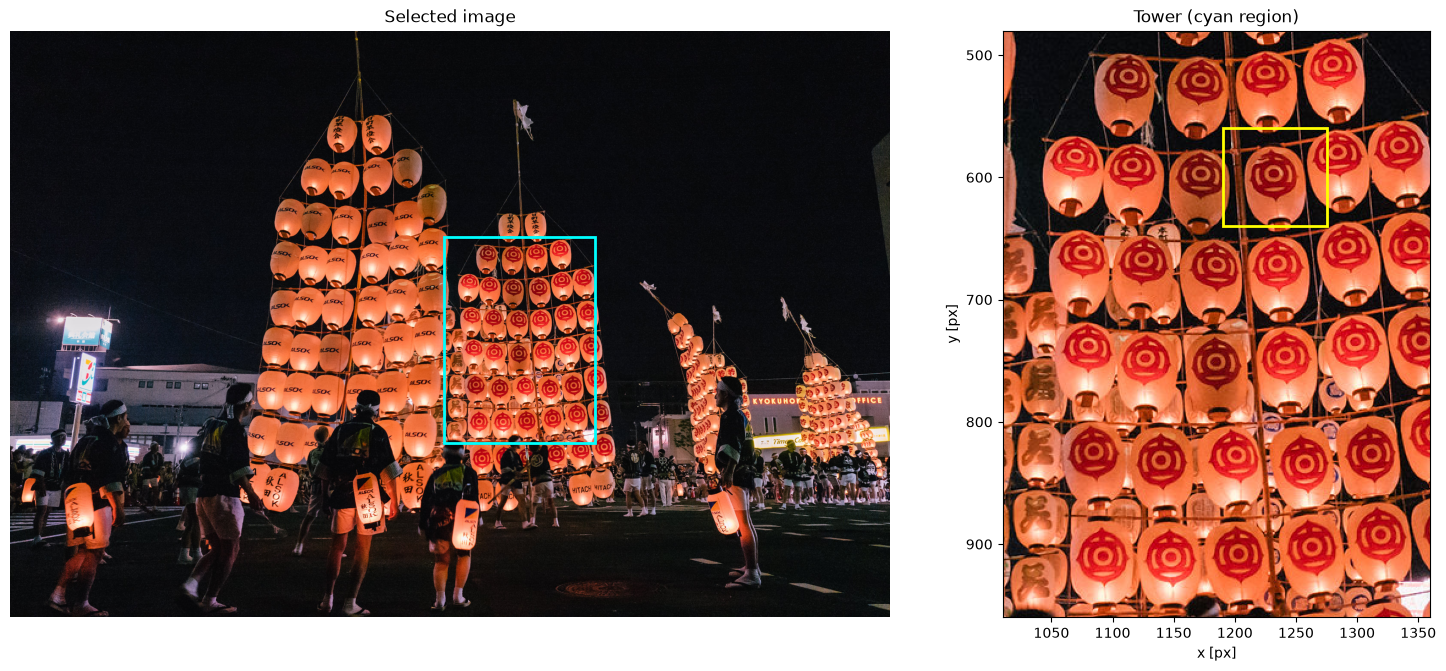

In [10]:
x0, x1, y0, y1 = TOWER
a, b, c, d = CREST
fig, axs = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={"width_ratios": [2.2, 1]})
axs[0].imshow(img)
axs[0].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="cyan", lw=2))
axs[0].set_title("Selected image"); axs[0].axis("off")
axs[1].imshow(img[y0:y1, x0:x1], extent=(x0, x1, y1, y0))
axs[1].add_patch(plt.Rectangle((a, c), b - a, d - c, fill=False, ec="yellow", lw=2))
axs[1].set_title("Tower (cyan region)"); axs[1].set_xlabel("x [px]"); axs[1].set_ylabel("y [px]")
plt.tight_layout(); plt.show()

**Figure 1.** Left: the image with the tower region (cyan). Right: the tower at original resolution with pixel coordinates; the crests form a regular grid of about eight rows with four to five crests each, crests in lower rows appear larger, and the yellow rectangle marks the crest analysed below. Some lanterns at the left edge carry lettering instead of a crest. Regions were chosen visually and are not algorithm outputs.

## 3. Pattern of interest
**Structure.** The outer boundary of the red crest on the lantern in the yellow rectangle: a closed, approximately circular contour with strong colour contrast to the surrounding paper.

**Detection target.** The shape of this contour as a circle, i.e. centre $(x,y)$ and radius $r$; not the lantern outline and not the inner details.

**Appearance.** Visual estimate: centre ≈ (1232, 598), outer radius ≈ 19–20 px. Inside, concentric structures follow (Figure 3). The contour deviates from a circle by a small tip at the bottom and a bump at the top.

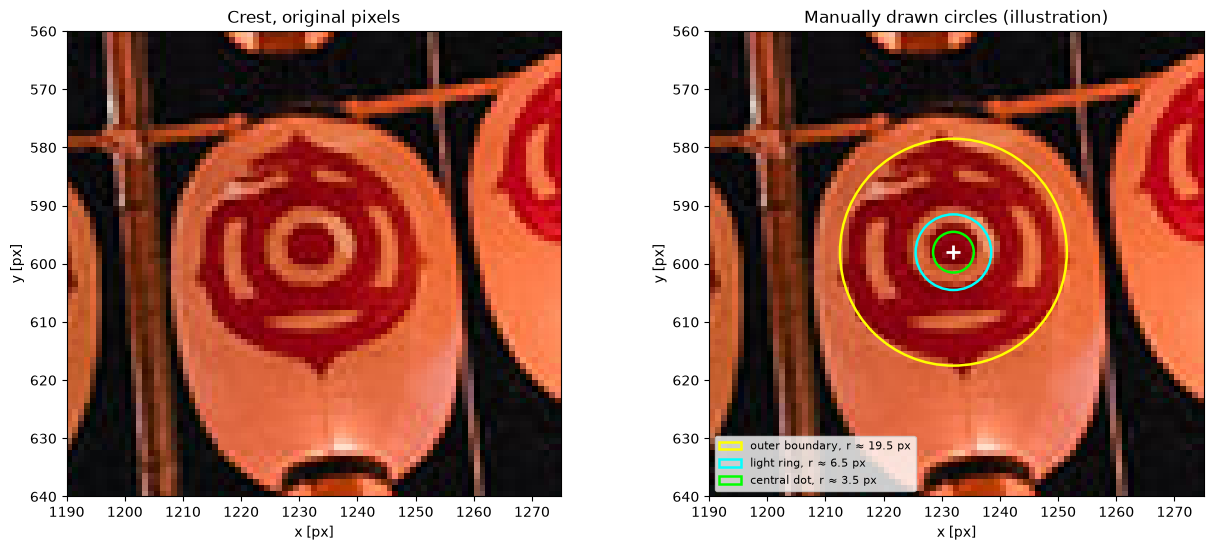

In [11]:
cx, cy = 1232, 598                                    # visually estimated crest centre
fig, axs = plt.subplots(1, 2, figsize=(13, 5.6))
for ax in axs:
    ax.imshow(img[c:d, a:b], extent=(a, b, d, c), interpolation="nearest")
    ax.set_xlabel("x [px]"); ax.set_ylabel("y [px]")
axs[0].set_title("Crest, original pixels")
for r, col, lab in [(19.5, "yellow", "outer boundary, r ≈ 19.5 px"), (6.5, "cyan", "light ring, r ≈ 6.5 px"), (3.5, "lime", "central dot, r ≈ 3.5 px")]:
    axs[1].add_patch(plt.Circle((cx, cy), r, fill=False, ec=col, lw=1.8, label=lab))
axs[1].plot(cx, cy, "w+", ms=10, mew=2); axs[1].legend(loc="lower left", fontsize=8)
axs[1].set_title("Manually drawn circles (illustration)")
plt.tight_layout(); plt.show()

**Figure 2.** Left: the crest at original pixel size without interpolation. Right: circles drawn manually from the radial profile of Figure 3 (outer boundary, light ring, central dot). They illustrate the concentric structure and the target size and are not the result of the Day 6 algorithm.

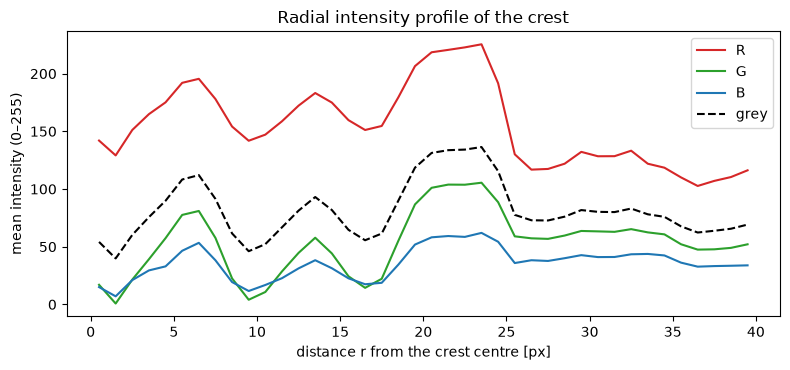

In [12]:
yy, xx = np.mgrid[c:d, a:b]
rad = np.hypot(xx - cx, yy - cy)
grey = 0.299 * img[c:d, a:b, 0] + 0.587 * img[c:d, a:b, 1] + 0.114 * img[c:d, a:b, 2]
r_axis = np.arange(0, 40)
fig, ax = plt.subplots(figsize=(8, 3.8))
for k, (n, col) in enumerate([("R", "tab:red"), ("G", "tab:green"), ("B", "tab:blue")]):
    ch = img[c:d, a:b, k].astype(float)
    ax.plot(r_axis + 0.5, [ch[(rad >= r) & (rad < r + 1)].mean() for r in r_axis], color=col, label=n)
ax.plot(r_axis + 0.5, [grey[(rad >= r) & (rad < r + 1)].mean() for r in r_axis], "k--", label="grey")
ax.set_xlabel("distance r from the crest centre [px]"); ax.set_ylabel("mean intensity (0–255)")
ax.set_title("Radial intensity profile of the crest"); ax.legend()
plt.tight_layout(); plt.show()

**Figure 3.** Mean channel intensity as a function of the distance $r$ from the crest centre. From the centre: dark dot (minimum at $r\approx1$–2 px), light ring (maximum at 6–7 px), dark ring (minimum at 9–10 px), light arcs (13–14 px), dark band (16–17 px), then a steep rise at $r\approx19$–20 px, which is the outer boundary, up to the paper plateau (to ≈ 24 px). Beyond ≈ 25 px the intensity falls at the lantern edge. All channels decrease inside the crest, with different relative contrast: red from ≈ 220 to ≈ 150 (≈ 30 %), green from ≈ 105 to ≈ 15 and blue from ≈ 60 to ≈ 15. The boundary contrast is thus lowest in the red channel and highest in green and blue; the grey image (green-weighted) lies in between.

## 4. Relevance, manifestation and objective
**Relevance.** One crest per lantern: crest count and positions give lantern count and grid; centre and radius provide a reference for cropping each lantern; the crest is the most compact, round and repeated structure of a lantern.

**Manifestation in the image.** Dozens of crests of varying size occur among elliptical lantern outlines and straight bars, with concentric inner edges, partial occlusion and glowing paper. Many edge pixels therefore do not belong to a crest boundary.

**Objective.** Localise the red crests as circles, returning centre and radius for each visible crest (shape-based boundary extraction), for counting and as anchors. The Hough circle transform of Day 6 operates on an edge map and accumulates evidence for $(x,y,r)$, which is the parametrisation of the target.

---
# Day 8 · Methodological Design

## 1. From edges to a geometric structure
The edge detection of Day 6 (Sobel, non-maximum suppression, threshold) marks every intensity transition. In the tower region these are the crest boundaries, the inner rings of the crests, the lantern outlines, the bamboo bars and noise. An edge pixel carries no information about whether it belongs to a circle.

The target is the **geometric structure**: the set of edge pixels that are jointly consistent with one circle $(x,y,r)$. The Hough transform provides this grouping by voting. Geometric knowledge enters through three constraints: the **radius range** (size prior), the **peak threshold** (required completeness of the circle) and the **minimum separation** (one detection per object).

## 2. Processing steps for the selected image
1. **Input channel: green.** The crest boundary contrast is lowest in R and highest in G and B (Figure 3). G is chosen because it combines high crest contrast (≈ 105 → 15) with a higher signal level than B (≈ 60 → 15), hence a better noise ratio. The grey image (green-weighted) would reduce the contrast of the crest edge relative to the lantern–sky edges.
2. **Region: tower region** (Figure 1). It contains the crests of interest and limits the number of competing structures and the size of the accumulator.
3. **Algorithm of Day 6 unchanged:** smoothing, Sobel, non-maximum suppression, edge map, voting, peak search.

## 3. Fixed settings
| Setting | Value | Justification |
|---|---|---|
| smoothing $\sigma$ | 1.5 px | suppresses noise (≈ ±5 levels) while the ring spacing (≈ 3 px) and the crest boundary remain resolvable; as in Day 6 |
| edge threshold `EDGE_FRAC` | 0.20 | relative to the maximum thinned magnitude; crest edges in G are expected to have a contrast comparable to the strongest edges (lantern against sky), whereas noise and paper texture are expected to lie well below |
| `MIN_SEP` | 15 px | adjacent crests are ≈ 55–60 px apart, concentric circles of one crest differ by less than 15 px in $(x,y,r)$ and are merged to one detection |
| radius step | 1 px | resolution of the accumulator, equal to the pixel size |

## 4. Key parameters
**Radius range $[r_{\min}, r_{\max}]$.** Crest radii in the tower region are ≈ 18–23 px (≈ 19 px at the top, ≈ 22 px at the bottom). The inner structure has radii ≈ 3.5, 6.5, 9–10 and 13–14 px (Figure 3); the lantern half-width is ≈ 25 px, but the lantern is an ellipse with a half-height of ≈ 45 px.
- *Expected effect of a range that excludes the inner radii:* one candidate circle per crest, fewer spurious votes, lower computational cost (proportional to the number of radii).
- *Expected effect of lowering $r_{\min}$ to include the inner radii:* additional circles at the same centres (ring edges), partly removed by `MIN_SEP`, and more random vote overlap.

**Peak threshold `PEAK_THR`.** The accumulator value is the fraction of the circumference covered by edge pixels (Day 6). The crest contour deviates from a circle (tip at the bottom, bump at the top, amplitude of a few pixels) and is partly occluded by bars, while the accumulator resolution is 1 px; the completeness of real crests is therefore expected to be lower than the values 0.85–0.95 of the synthetic test.
- *Expected effect of a high threshold:* only nearly complete circles are accepted; deformed or occluded crests are missed.
- *Expected effect of a low threshold:* partly occluded crests are accepted, but also arcs of lantern outlines and clutter, i.e. false detections.

## 5. Configurations
One parameter is changed per variation, so differences can be attributed to a single cause.

| ID | Radius range [px] | `PEAK_THR` | Purpose |
|---|---|---|---|
| **P0** baseline | 15–28 | 0.50 | covers the crest radii (≈ 18–23 px) with a margin of about 20 %, excludes inner rings; at least half of the circumference required |
| **P1** wide radii | **8–28** | 0.50 | tests the influence of the concentric inner rings and of a larger search space |
| **P2** low threshold | 15–28 | **0.30** | tests the trade-off between detecting deformed or occluded crests and false detections |

The baseline combines a size prior derived from the image with a moderate completeness requirement; P1 and P2 span the two parameter axes in the direction that is expected to increase the number of detections.

In [13]:
# Specification only (applied and evaluated on Day 9); fixed settings are shared by all configurations
FIXED = dict(channel="G", region="tower region", sigma=1.5, edge_frac=0.20, min_sep=15, radius_step=1)
CONFIGS_HOUGH = {
    "P0 baseline":      dict(r_min=15, r_max=28, peak_thr=0.50),
    "P1 wide radii":    dict(r_min=8,  r_max=28, peak_thr=0.50),
    "P2 low threshold": dict(r_min=15, r_max=28, peak_thr=0.30),
}
print("fixed:", FIXED, "\n")
print(f"{'configuration':<18}{'radius range [px]':>19}{'radii':>7}{'PEAK_THR':>10}")
for n, p in CONFIGS_HOUGH.items():
    print(f"{n:<18}{str(p['r_min']) + '-' + str(p['r_max']):>19}{p['r_max'] - p['r_min'] + 1:>7}{p['peak_thr']:>10}")

fixed: {'channel': 'G', 'region': 'tower region', 'sigma': 1.5, 'edge_frac': 0.2, 'min_sep': 15, 'radius_step': 1} 

configuration       radius range [px]  radii  PEAK_THR
P0 baseline                     15-28     14       0.5
P1 wide radii                    8-28     21       0.5
P2 low threshold                15-28     14       0.3


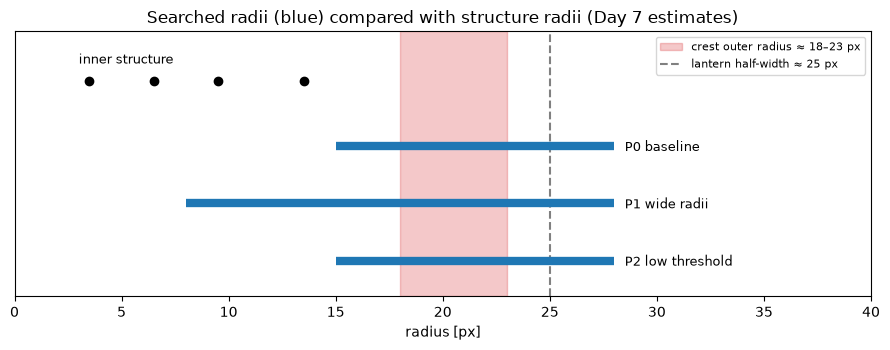

In [14]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.axvspan(18, 23, color="tab:red", alpha=0.25, label="crest outer radius ≈ 18–23 px")
ax.axvline(25, color="gray", ls="--", label="lantern half-width ≈ 25 px")
for r in [3.5, 6.5, 9.5, 13.5]:
    ax.plot(r, 3.3, "ko", ms=6)
ax.text(3, 3.55, "inner structure", fontsize=9)
for y, (n, p) in zip([2.4, 1.6, 0.8], CONFIGS_HOUGH.items()):
    ax.hlines(y, p["r_min"], p["r_max"], lw=6, color="tab:blue"); ax.text(p["r_max"] + 0.5, y - 0.07, n, fontsize=9)
ax.set_xlim(0, 40); ax.set_ylim(0.3, 4); ax.set_yticks([]); ax.set_xlabel("radius [px]")
ax.set_title("Searched radii (blue) compared with structure radii (Day 7 estimates)"); ax.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

**Figure 4.** Design diagram, not a result. The red band is the estimated range of crest outer radii in the tower region, the dashed line the lantern half-width, the black points the radii of the inner structure (Figure 3). The blue bars are the radius ranges of the configurations. P0 and P2 cover the crest radii and exclude the inner radii; P1 additionally covers the inner radii. The lantern half-width lies within all ranges, so lantern outlines are rejected only through their elliptical shape (low circle completeness), i.e. through `PEAK_THR`.

---
# Day 9 · Evaluation

## 1. Application of the configurations
The configurations of Day 8 are applied to the tower region (green channel, `FIXED` settings). The edge map and the accumulator do not depend on the configuration and are computed once (radii 8–28 px); the peak search is run for each configuration on its own radius slice and threshold.

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage as ndi

x0, x1, y0, y1 = TOWER
G = img[y0:y1, x0:x1, 1].astype(float)                                   # green channel, tower region
blurred_t = smooth(G, FIXED["sigma"])
_, _, mag_t, ang_t = sobel(blurred_t)
edges_t = edge_map(non_max_suppression(mag_t, ang_t), FIXED["edge_frac"])
R_ALL = np.arange(8, 29)
acc_t = hough_circle_accumulator(edges_t, R_ALL)                          # computed once, shape (21, h, w)

detections = {}
for name, p in CONFIGS_HOUGH.items():
    sl = slice(p["r_min"] - R_ALL[0], p["r_max"] - R_ALL[0] + 1)
    found = find_circles(acc_t[sl], R_ALL[sl], p["peak_thr"], FIXED["min_sep"])
    detections[name] = [(cx + x0, cy + y0, r, v) for cx, cy, r, v in found]   # full-image coordinates
    print(f"{name:<18} detections in the tower region: {len(detections[name])}")
print(f"edge pixels: {int(edges_t.sum())}, accumulator shape: {acc_t.shape}")

P0 baseline        detections in the tower region: 27


P1 wide radii      detections in the tower region: 42


P2 low threshold   detections in the tower region: 251
edge pixels: 24823, accumulator shape: (21, 480, 350)


## 2. Reference
**Manual annotation.** The crest centres in the tower region were marked by visual inspection of the image on a pixel grid (estimated uncertainty ≈ ±3 px), independently of any detection result. Only crests that lie completely inside the region are included (centre ≥ 22 px from the region border, i.e. more than the largest crest radius); lanterns with lettering and cut-off crests are excluded. The reference contains 30 crests.

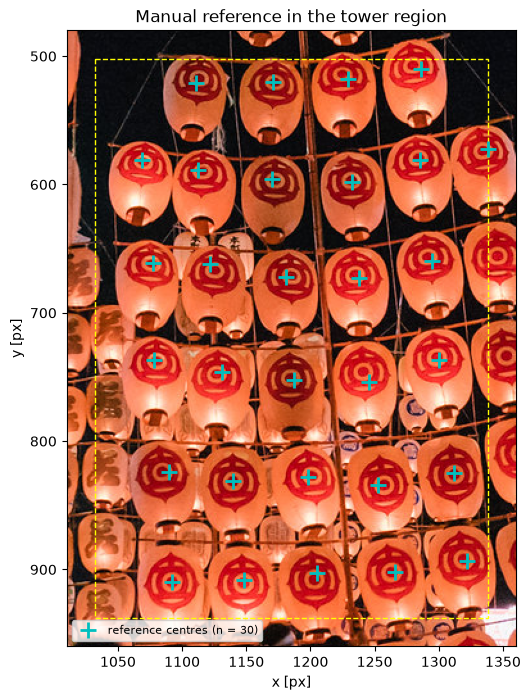

In [16]:
REFERENCE = [  # (x, y) crest centres, original pixel coordinates, rows from top to bottom
    (1111, 521), (1171, 520), (1229, 518), (1286, 510),
    (1069, 581), (1112, 589), (1170, 596), (1232, 598), (1285, 581), (1338, 572),
    (1077, 661), (1122, 662), (1181, 672), (1238, 673), (1295, 660),
    (1078, 737), (1131, 746), (1187, 752), (1246, 754), (1300, 737),
    (1090, 824), (1140, 831), (1198, 828), (1253, 834), (1312, 825),
    (1092, 910), (1148, 908), (1205, 903), (1266, 902), (1322, 893),
]
MARGIN = 22                                            # px: evaluation area = region minus this margin
inside = lambda x, y: x0 + MARGIN <= x <= x1 - MARGIN and y0 + MARGIN <= y <= y1 - MARGIN
assert all(inside(x, y) for x, y in REFERENCE)

fig, ax = plt.subplots(figsize=(6.2, 8))
ax.imshow(img[y0:y1, x0:x1], extent=(x0, x1, y1, y0))
ax.plot(*zip(*REFERENCE), "c+", ms=12, mew=2, label=f"reference centres (n = {len(REFERENCE)})")
ax.add_patch(plt.Rectangle((x0 + MARGIN, y0 + MARGIN), x1 - x0 - 2 * MARGIN, y1 - y0 - 2 * MARGIN, fill=False, ec="yellow", ls="--"))
ax.legend(loc="lower left", fontsize=8); ax.set_xlabel("x [px]"); ax.set_ylabel("y [px]")
ax.set_title("Manual reference in the tower region")
plt.show()

**Figure 5.** Reference crest centres (cyan crosses) on the tower region; the yellow dashed rectangle is the evaluation area (region minus a margin of 22 px). Each cross is the visually estimated centre of the crest.

## 3. Evaluation measure: F1 score
**Matching.** Detections whose centre lies in the evaluation area are processed in descending accumulator value. A detection is a *true positive* (TP) if its centre is within 8 px (≈ 0.4 crest radius) of a reference centre that has not yet been matched; the reference is then marked as matched. Every other detection, including a second detection at an already matched crest, is a *false positive* (FP). Reference crests without a detection are *false negatives* (FN). The radius is not scored.

**Definition.**
$$F_1=\frac{2\,P\,R}{P+R}=\frac{2\,\mathrm{TP}}{2\,\mathrm{TP}+\mathrm{FP}+\mathrm{FN}},\qquad P=\frac{\mathrm{TP}}{\mathrm{TP}+\mathrm{FP}},\quad R=\frac{\mathrm{TP}}{\mathrm{TP}+\mathrm{FN}}$$
$F_1\in[0,1]$; 1 means that every reference crest is found once and nothing else is reported.

**Justification.** The objective (Day 7) is to localise crests for counting and as anchors. Missed crests (FN) and false detections (FP) both falsify the count and the lantern grid. The configurations of Day 8 shift the two errors in opposite directions (threshold, radius range), which a plain detection count cannot reveal and which $F_1$ combines into one bounded value. It is independent of internal quantities such as the accumulator value and therefore comparable between configurations with different thresholds. TP, FP and FN are reported as the quantities from which $F_1$ is computed.

In [17]:
def evaluate(dets, reference, tol=8.0):
    ins = [d for d in dets if inside(d[0], d[1])]                         # evaluation area only
    free, tp_d, fp_d = list(reference), [], []
    for d in sorted(ins, key=lambda d: -d[3]):                            # descending accumulator value
        dist = [np.hypot(d[0] - rx, d[1] - ry) for rx, ry in free]
        if dist and min(dist) <= tol:
            free.pop(int(np.argmin(dist))); tp_d.append(d)
        else:
            fp_d.append(d)
    tp, fp, fn = len(tp_d), len(fp_d), len(free)
    return dict(n=len(ins), tp=tp, fp=fp, fn=fn, f1=2 * tp / (2 * tp + fp + fn), tp_dets=tp_d, fp_dets=fp_d, missed=free)

results9 = {n: evaluate(d, REFERENCE) for n, d in detections.items()}
base = results9["P0 baseline"]["f1"]
print(f"{'configuration':<18}{'evaluated':>10}{'TP':>5}{'FP':>5}{'FN':>5}{'F1':>8}{'dF1 vs P0':>11}{'% of P0':>9}")
for n, r in results9.items():
    print(f"{n:<18}{r['n']:>10}{r['tp']:>5}{r['fp']:>5}{r['fn']:>5}{r['f1']:>8.3f}{r['f1'] - base:>+11.3f}{100 * r['f1'] / base:>8.1f}%")

configuration      evaluated   TP   FP   FN      F1  dF1 vs P0  % of P0
P0 baseline               27   25    2    5   0.877     +0.000   100.0%
P1 wide radii             39   28   11    2   0.812     -0.066    92.5%
P2 low threshold         236   29  207    1   0.218     -0.659    24.9%


## 4. Results
**Table.** For each configuration: number of evaluated detections (centre in the evaluation area), TP, FP, FN, $F_1$, the difference to the baseline P0 ($\Delta F_1$) and $F_1$ as a percentage of the baseline. The reference contains 30 crests; TP + FN = 30 for every configuration.

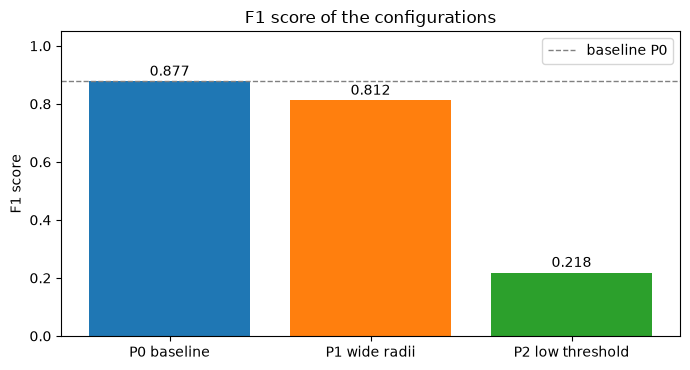

In [18]:
names = list(results9); f1s = [results9[n]["f1"] for n in names]
fig, ax = plt.subplots(figsize=(7, 3.8))
bars = ax.bar(names, f1s, color=["tab:blue", "tab:orange", "tab:green"])
for b_, v in zip(bars, f1s): ax.text(b_.get_x() + b_.get_width() / 2, v + 0.02, f"{v:.3f}", ha="center")
ax.axhline(base, color="gray", ls="--", lw=1, label="baseline P0")
ax.set_ylim(0, 1.05); ax.set_ylabel("F1 score"); ax.set_title("F1 score of the configurations"); ax.legend()
plt.tight_layout(); plt.show()

**Figure 6.** $F_1$ per configuration (bars, value above each bar); the dashed line marks the baseline P0. All bars use the same measure, the same reference and the same evaluation area; exact differences are given in the table above.

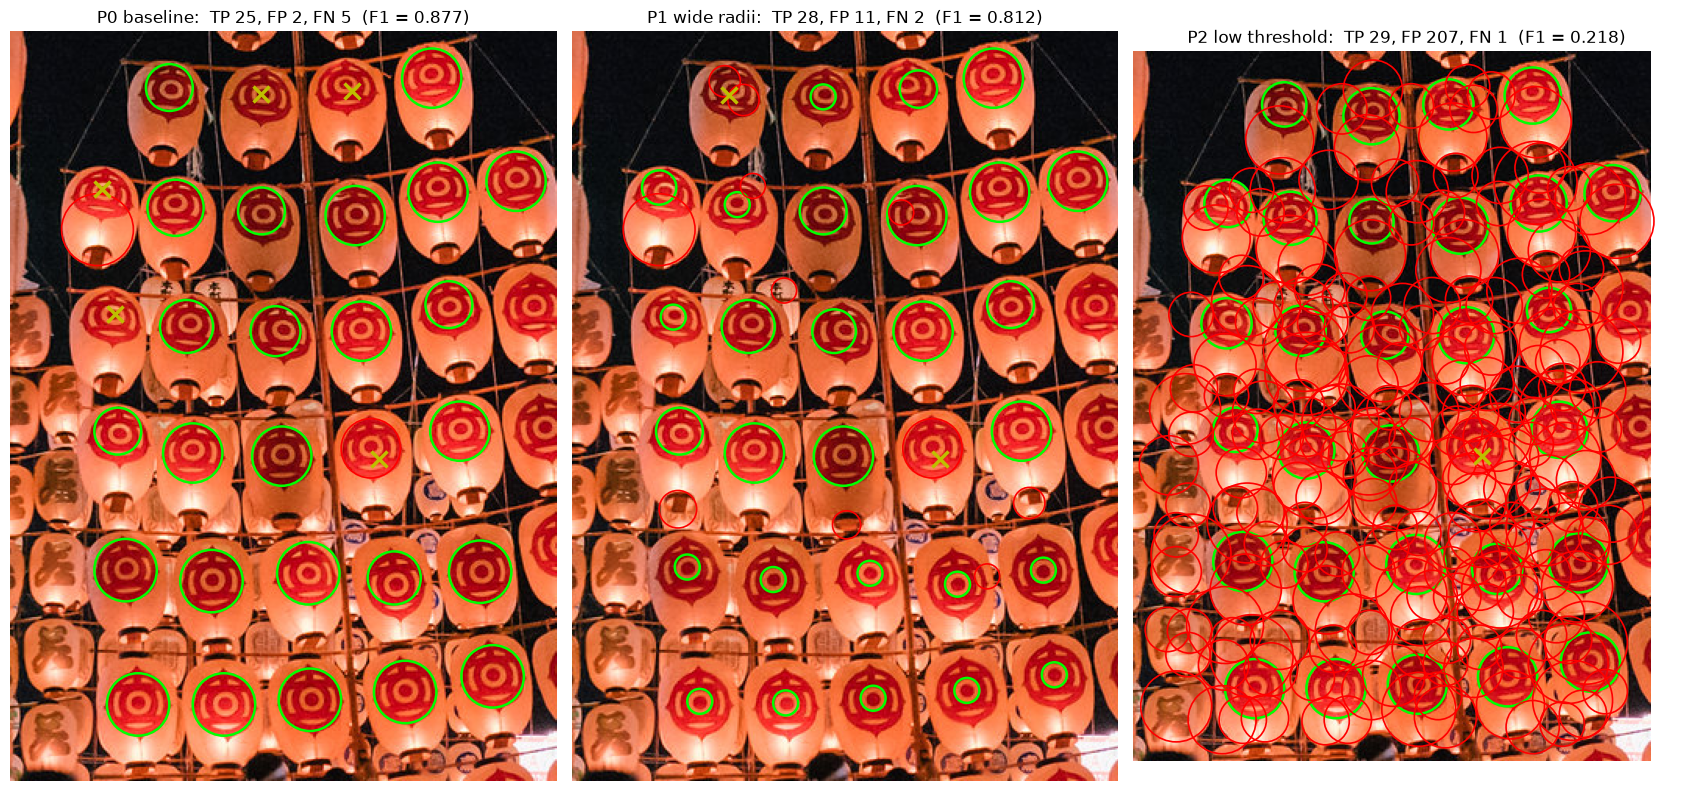

In [19]:
fig, axs = plt.subplots(1, 3, figsize=(17, 8))
for ax, (n, r_) in zip(axs, results9.items()):
    ax.imshow(img[y0:y1, x0:x1], extent=(x0, x1, y1, y0))
    for d in r_["tp_dets"]: ax.add_patch(plt.Circle((d[0], d[1]), d[2], fill=False, ec="lime", lw=1.8))
    for d in r_["fp_dets"]: ax.add_patch(plt.Circle((d[0], d[1]), d[2], fill=False, ec="red", lw=1.2))
    for rx, ry in r_["missed"]: ax.plot(rx, ry, "yx", ms=11, mew=2.5)
    ax.set_title(f"{n}:  TP {r_['tp']}, FP {r_['fp']}, FN {r_['fn']}  (F1 = {r_['f1']:.3f})"); ax.axis("off")
plt.tight_layout(); plt.show()

**Figure 7.** Detections of the three configurations on the tower region. Green circles: true positives; red circles: false positives (centre in the evaluation area); yellow crosses: reference crests without a detection (false negatives). Circle radius is the detected radius; in P1 several true positives have radii clearly below the crest radius (circles on inner rings), since the radius is not scored. The counts in the titles correspond to the table.

---
# Day 10 · Analytical & Communication

**Observations.** With 30 reference crests, F1 was 0.877 for P0 (TP 25, FP 2, FN 5), 0.812 for P1 (28, 11, 2; ΔF1 = −0.066) and 0.218 for P2 (29, 207, 1; ΔF1 = −0.659).

**Interpretation.** Lowering `PEAK_THR` from 0.5 to 0.3 accepts cells supported by only 30 % of a circumference. Arcs of the elliptical lantern outlines (inside the radius range) and other curved edges reach this level, giving 207 FP, while four more crests with deformed contours are matched. Extending the radii to 8 px admits the concentric inner rings, which are closer to perfect circles than the crest contour; crests missed by P0 are found (FN 5 → 2), but ring and clutter circles raise FP to 11.

**Discussion and critical reflection.** P0 is the only configuration suitable for counting (27 detections for 30 crests); P2 is unusable (236 detections). The peak threshold dominates the outcome, the radius range has a smaller, mixed effect. Limitations: one image, one annotator, centre-only matching, so P1 gains TP from small ring circles, and σ and the edge threshold were not varied. F1 weights FP and FN equally and ignores radius accuracy, so it only partly captures the objective; transfer to other towers or lighting is untested.